# One Hidden Layer

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

# Parameters

In [2]:
inpDir = '../input'
outDir = '../output'

RANDOM_STATE = 24 # REMEBER : TO REMOVE AT THE TIME OF PROMOTION TO PRODUCTION
# np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
EPOCHS = 20001
ALPHA = 0.0001 #lr
N_SAMPLES = 1000 #no of sample to create 
TEST_SIZE = 0.2


params = { 'legend.fontsize': 'medium',
           'figure.figsize':(15,6),
           'axes.labelsize':'medium',
           'axes.titlesize':'medium',
           'xtick.labelsize': 'medium',
           'ytick.labelsize': 'medium'
}

plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

# Helper Function

In [3]:
def plot_decision_boundary(model : dict,
                           X_tr : np.ndarray,
                           y_tr : np.ndarray,
                           X_ts : np.ndarray,
                           y_ts : np.ndarray):

    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    
    xMin = min(X_tr[:,0].min() - margin, X_ts[:,0].min() - margin)
    xMax = max(X_tr[:,0].max() + margin, X_ts[:,0].max() + margin)
    yMin = min(X_tr[:, 1].min() - margin, X_ts[:, 1].min() - margin)
    yMax = max(X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)
    xx, yy = np.meshgrid(np.arange(xMin, xMax, dm),
                        np.arange(yMin, yMax, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]

    Z = fn_predict(model, XX).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    
    ax.scatter(X_tr[:,0], 
               X_tr[:,1], 
               c = y_tr, 
               s = 30, 
               edgecolors='k',
               cmap = CMAP)
    
    ax.scatter(X_ts[:,0], 
               X_ts[:,1], 
               c = y_ts, 
               s = 30, 
               marker = "*",
               edgecolors='k',
               cmap = plt.cm.seismic)
    
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title("Decision Boundary")
    ax.legend()

# Load Dataset

In [4]:
X, y = datasets.make_moons(n_samples=N_SAMPLES,
                           shuffle=True,
                           noise=NOISE,
                           random_state=RANDOM_STATE)
X[:5], y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [5]:
train_test_split?

Signature:
train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
)
Docstring:
Split arrays or matrices into random train and test subsets.

Quick utility that wraps input validation,
``next(ShuffleSplit().split(X, y))``, and application to input data
into a single call for splitting (and optionally subsampling) data into a
one-liner.

Read more in the :ref:`User Guide <cross_validation>`.

Parameters
----------
*arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
    Indexable data-structures can be arrays, lists, dataframes, scipy
    sparse matrices or pandas dataframes with consistent first dimension.

test_size : float or int, default=None
    If float, should be between 0.0 and 1.0 and represent the proportion
    of the dataset to include in the test split. If int, represents the
    absolute number of test samples. If None, the value is set to the
    complement 

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=TEST_SIZE, 
                                                    random_state=RANDOM_STATE, 
                                                    stratify=y)

In [7]:
df = pd.DataFrame(data=X, columns=['A','B']) #Convert to dataframe
df['target'] = y
df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [8]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 2) (200, 2) (800,) (200,)


# Different Plots

<Axes: xlabel='A', ylabel='B'>

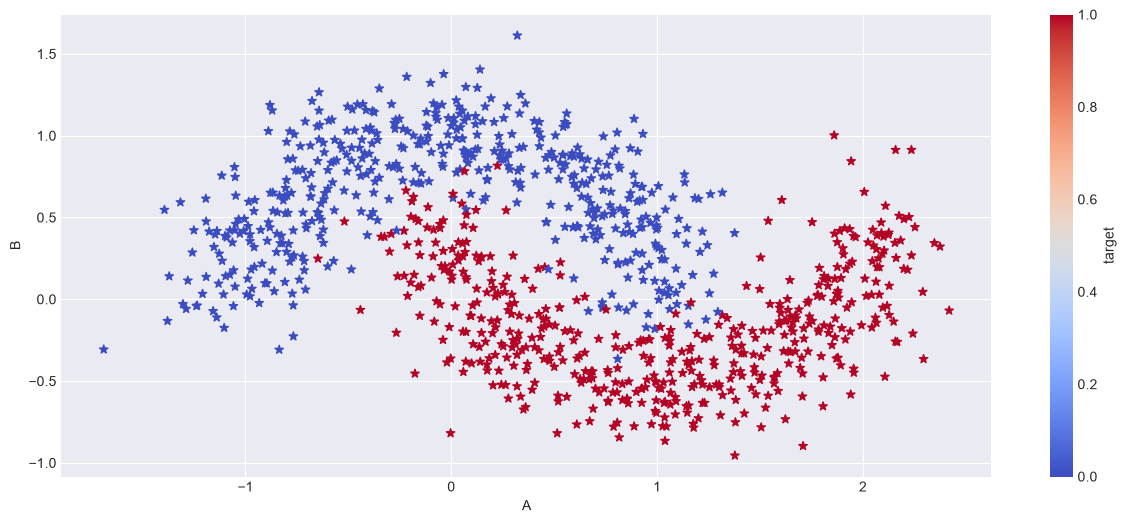

In [9]:
df.plot.scatter('A','B',s=40,marker="*",c='target',cmap='coolwarm')

# Sigmoid Function

In [10]:
def fn_sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [11]:
fn_sigmoid(np.asarray([-np.inf, -1, 0, +1, np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

# Tanh Activation Function

In [12]:
def fn_activ(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z: np.ndarray) -> np.ndarray:
    return 1.0 - np.tanh(z)**2

In [13]:
fn_activ(np.asarray([[-1,0,-1],[-np.inf,0,np.inf]]))

array([[-0.76159416,  0.        , -0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [14]:
def fn_predict(model:dict, X_p:np.ndarray):
    '''
    Model : Dict Containing weights and bias
    X : Input Features
    '''
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # Forward propogation

    # Layer 1
    z1 = X_p.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_sigmoid(z2) #Activation
    
    return a2 >= 0.5

In [15]:
def fn_calculate_loss(model: dict,  X_l:  np.ndarray, y_l: np.ndarray):
    '''
    Model : Dict Containing weights and bias
    X : Input Features
    y_l : target
    '''
    m = X_l.shape[0]
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # Forward propogation

    # Layer 1
    z1 = X_l.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_sigmoid(z2) #Activation

    data_loss = -(y_l * np.log(a2) + ( 1 - y_l ) * np.log( 1 - a2 )).sum()

    return data_loss / m

In [16]:
# weights = np.array([0.1,2.0,1.0])

# display(df.iloc[0])
# fn_predict(df.iloc[0].values, weights)
# single_sample = df.iloc[0][['A', 'B']].values.reshape(1, -1)
# prediction = fn_predict(model, single_sample)
# print("Prediction:", prediction)

In [17]:
def fn_build_model(nn_hdim : np.int64, 
                   X: np.ndarray,
                   y: np.ndarray,
                   alpha: np.float64=ALPHA,
                   n_epochs: np.int64=EPOCHS) -> dict:
    '''
    nn_hdim :number of hidden units 
    X: features
    y: labels/target
    alpha: learning rate
    n_epochs: number of passes through complete data for gradient descent
    '''
    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]

    W1 = rng.random((nn_input_dim, nn_hdim), dtype=np.float32) / np.sqrt(nn_input_dim)
    W2 = rng.random((nn_hdim, nn_output_dim), dtype=np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1, nn_hdim), dtype=np.float32)
    b2 = np.zeros((1, nn_output_dim), dtype=np.float32)

    curr_loss = 0
    loss, epoch = [],[]

    for i in range(n_epochs):
        # Forward Propogation
        
        # Layer 1
        z1 = X.dot(W1) + b1 # Aggregation
        a1 = fn_activ(z1) # Activation
    
        # Layer 2
        z2 = a1.dot(W2) + b2 # Aggregation
        a2 = fn_sigmoid(z2) #Activation

        # Back Propogation
        
        # Layer2
        
        dz2 = a2 - y
        dW2 = (a1.T).dot(dz2)
        # assert condition, "Optional error message if condition fails"
        assert (W2.shape == dW2.shape), f'Shape - W2:{W2.shape} | dW2:{dW2.shape}'

        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape - b2:{b2.shape} | db2:{db2.shape}'

        da1 = dz2.dot(W2.T)
        assert (a1.shape == da1.shape), f'Shape - a1:{a1.shape} | da1:{da1.shape}'

        # Layer 1
        dz1 = da1*fn_activ_prime(z1)
        dW1 = (X.T).dot(dz1)
        assert (W1.shape == dW1.shape), f'Shape - W1:{W1.shape} | dW1:{dW1.shape}'

        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape - b1:{b1.shape} | db1:{db1.shape}'

        
        W1 -= alpha * dW1 / m
        b1 -= alpha * db1 / m
        W2 -= alpha * dW2 / m
        b2 -= alpha * db2 / m

        model = {"W1": W1, "W2": W2, "b1": b1, "b2": b2}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model, X_l = X, y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")
            
    loss_hist["epoch"] = epoch
    loss_hist["loss"] = loss
    return model

In [18]:
loss_hist = {}
y_train = y_train.reshape([-1,1])
model = fn_build_model(500, X_train, y_train)

Epoch   0: Loss = 1.6266
Epoch 100: Loss = 1.5442
Epoch 200: Loss = 1.4635
Epoch 300: Loss = 1.3849
Epoch 400: Loss = 1.3085
Epoch 500: Loss = 1.2348
Epoch 600: Loss = 1.1640
Epoch 700: Loss = 1.0964
Epoch 800: Loss = 1.0325
Epoch 900: Loss = 0.9726
Epoch 1000: Loss = 0.9170
Epoch 1100: Loss = 0.8660
Epoch 1200: Loss = 0.8197
Epoch 1300: Loss = 0.7782
Epoch 1400: Loss = 0.7413
Epoch 1500: Loss = 0.7090
Epoch 1600: Loss = 0.6809
Epoch 1700: Loss = 0.6565
Epoch 1800: Loss = 0.6355
Epoch 1900: Loss = 0.6174
Epoch 2000: Loss = 0.6018
Epoch 2100: Loss = 0.5882
Epoch 2200: Loss = 0.5763
Epoch 2300: Loss = 0.5659
Epoch 2400: Loss = 0.5565
Epoch 2500: Loss = 0.5481
Epoch 2600: Loss = 0.5404
Epoch 2700: Loss = 0.5334
Epoch 2800: Loss = 0.5269
Epoch 2900: Loss = 0.5208
Epoch 3000: Loss = 0.5151
Epoch 3100: Loss = 0.5097
Epoch 3200: Loss = 0.5046
Epoch 3300: Loss = 0.4997
Epoch 3400: Loss = 0.4950
Epoch 3500: Loss = 0.4906
Epoch 3600: Loss = 0.4863
Epoch 3700: Loss = 0.4822
Epoch 3800: Loss = 0.4

<Axes: xlabel='epoch'>

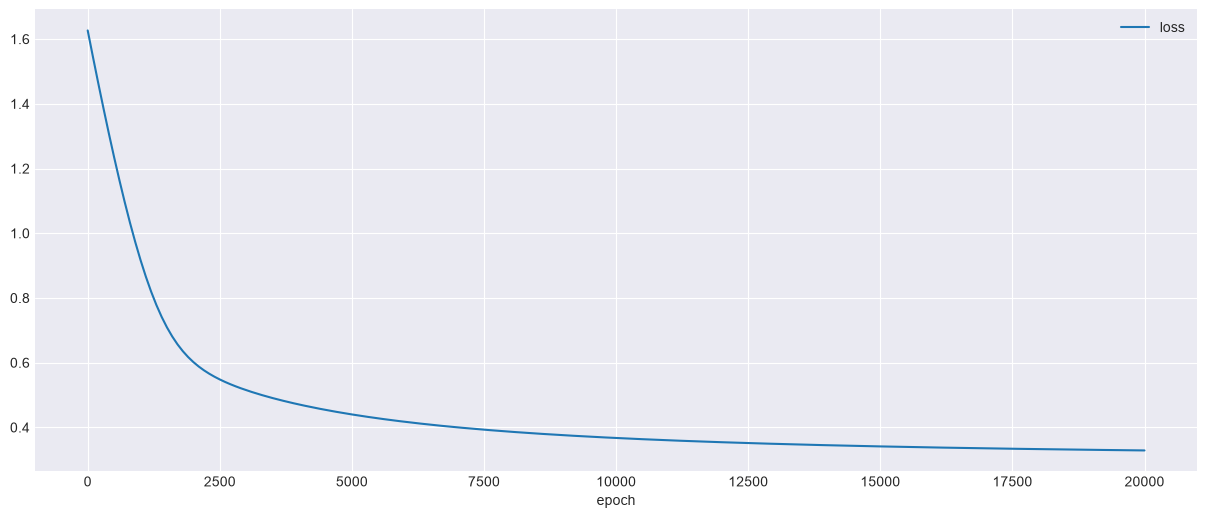

In [19]:
loss_df = pd.DataFrame(loss_hist)
fig, ax = plt.subplots()
loss_df.plot(x = 'epoch', y = 'loss', ax = ax)

In [20]:
y_pred = fn_predict(model=model, X_p=X_train)
f1_Score = f1_score(y_true=y_train, y_pred=y_pred, average='weighted')
train_acc = accuracy_score(y_train, y_pred)  # Changed variable name from accuracy_score to train_acc

print(f"Train F1-Score: {f1_Score:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")

Train F1-Score: 0.8687
Train Accuracy: 0.8688


In [21]:
y_pred_test = fn_predict(model=model, X_p=X_test)

test_f1 = f1_score(y_true=y_test, y_pred=y_pred_test, average='weighted')
test_acc = accuracy_score(y_test, y_pred_test)  # Now uses the intact accuracy_score function safely

print(f"Test F1-Score: {test_f1:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test F1-Score: 0.8447
Test Accuracy: 0.8450


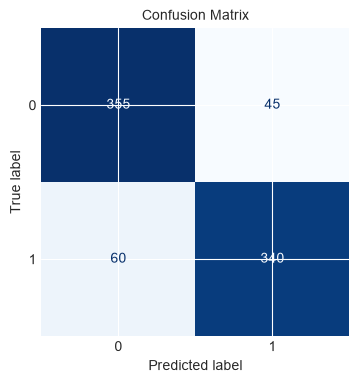

In [22]:
cm = confusion_matrix(y_train, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)  # Pass ax=ax to prevent overlapping plots
plt.title("Confusion Matrix")
plt.show()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_27236\3142969964.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


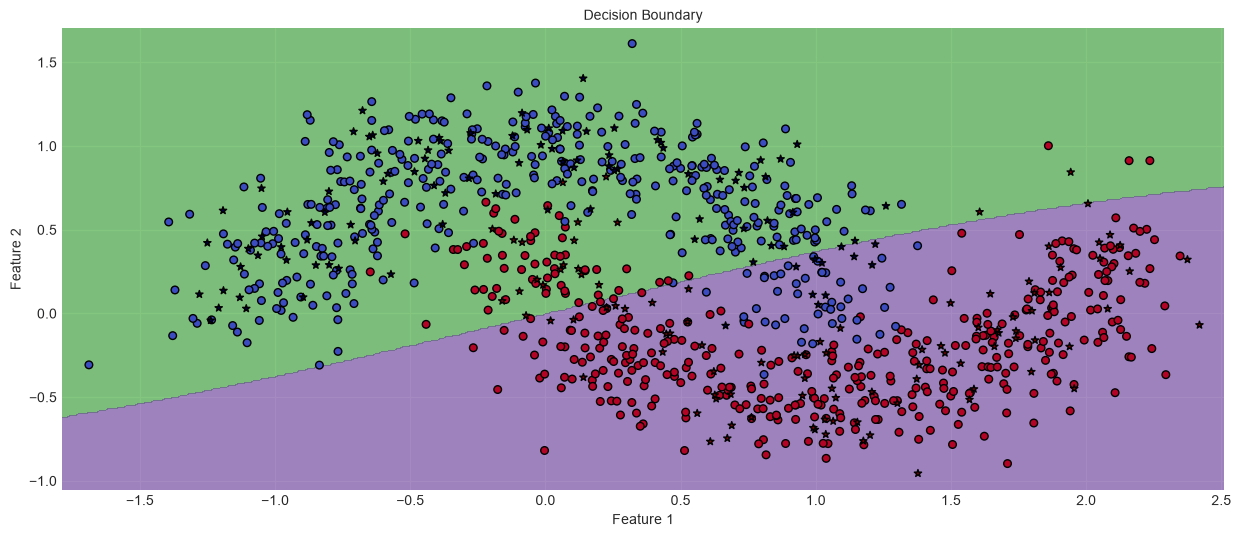

In [23]:
plot_decision_boundary(model, X_train, y_train, X_test, y_test)

----------------------
----------------------
----------------------
# FOR LR = 1, NOISE = 0.2, DIM OF HL = 1
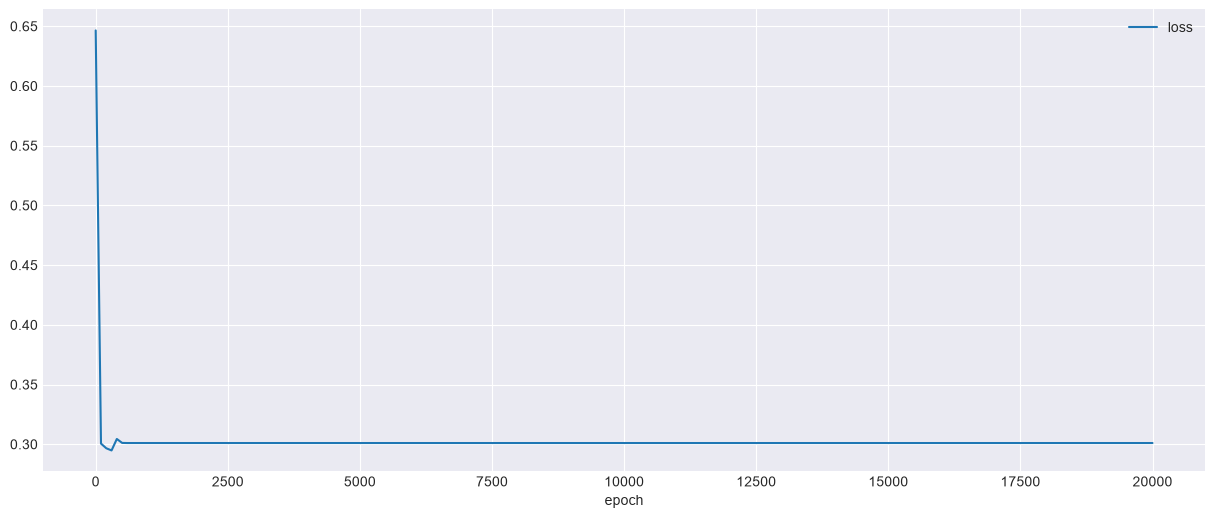


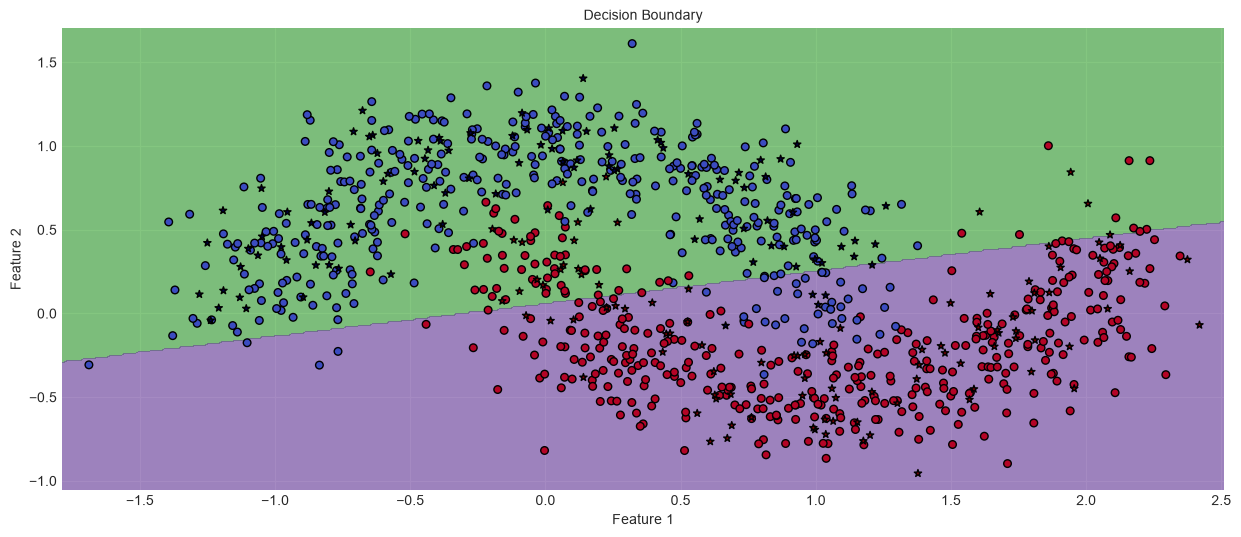

--------------
# FOR LR = 0.1, NOISE = 0.2, DIM OF HL = 2

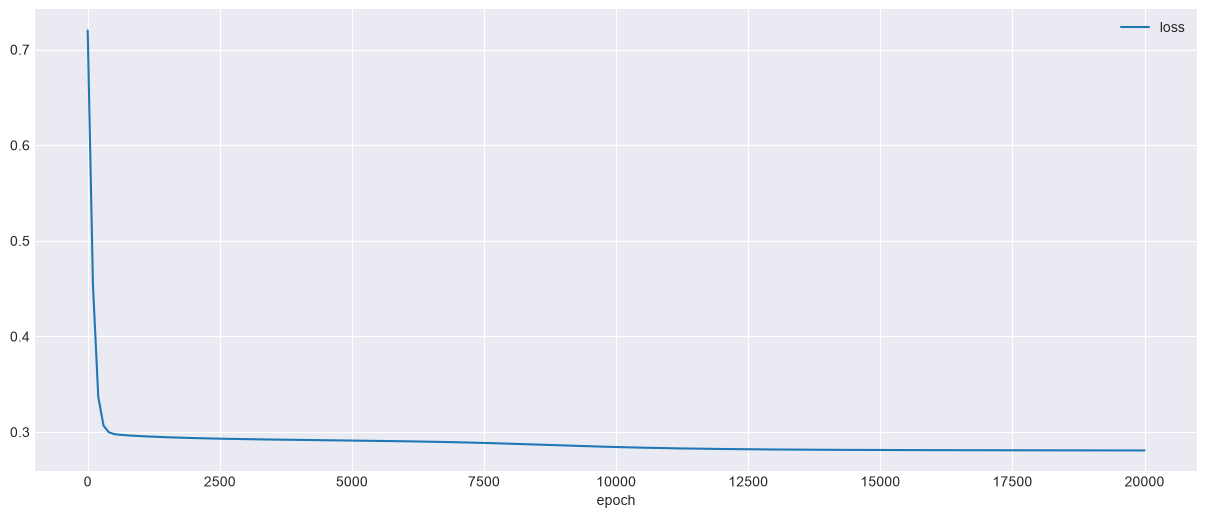


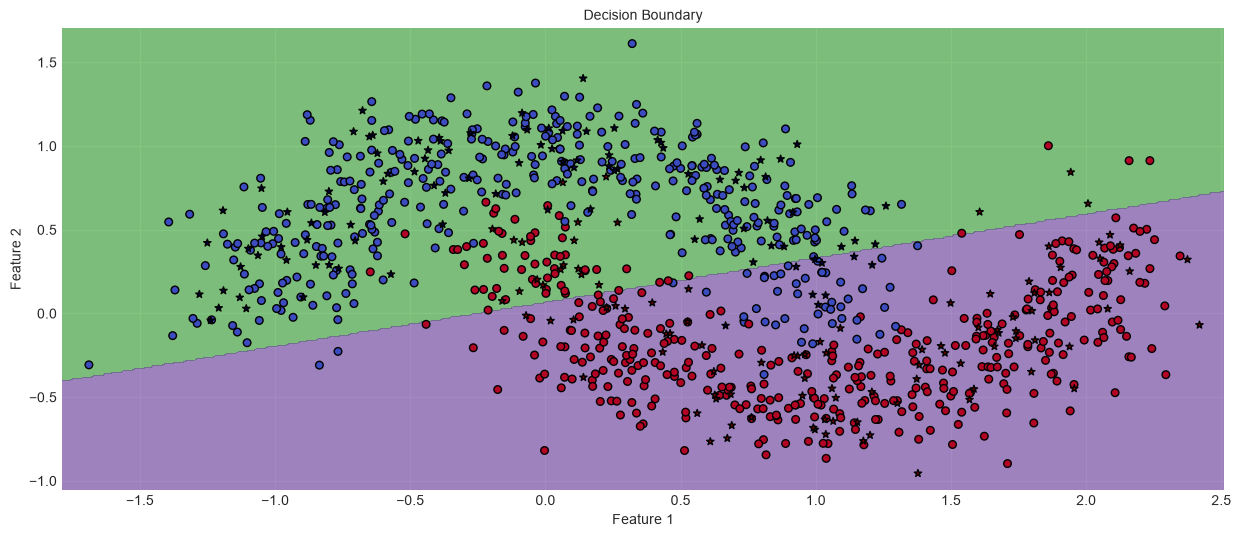

----------------------
# FOR LR = 0.1, NOISE = 0.2, DIM OF HL = 3

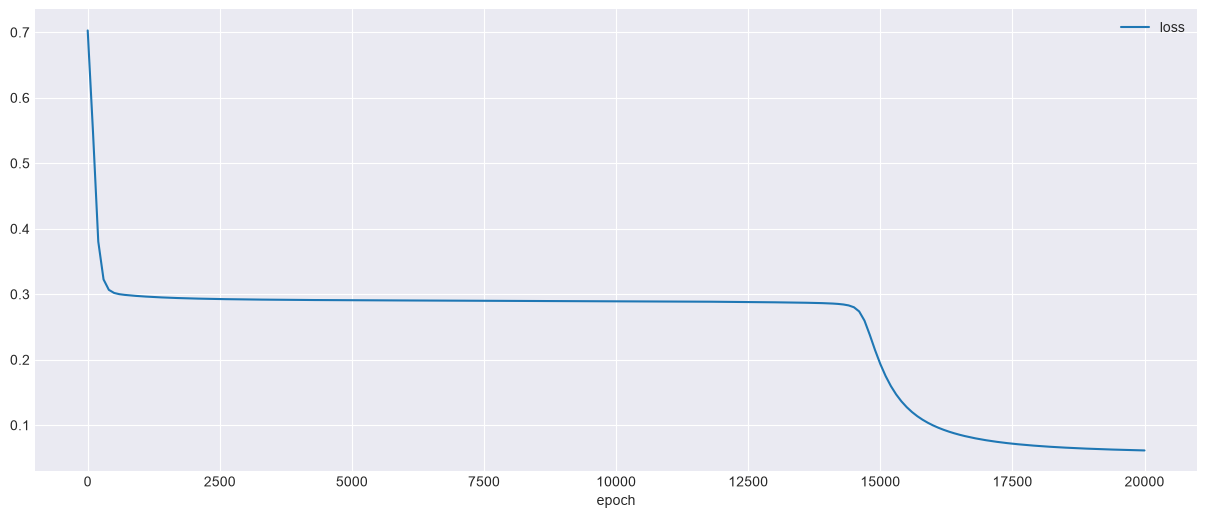

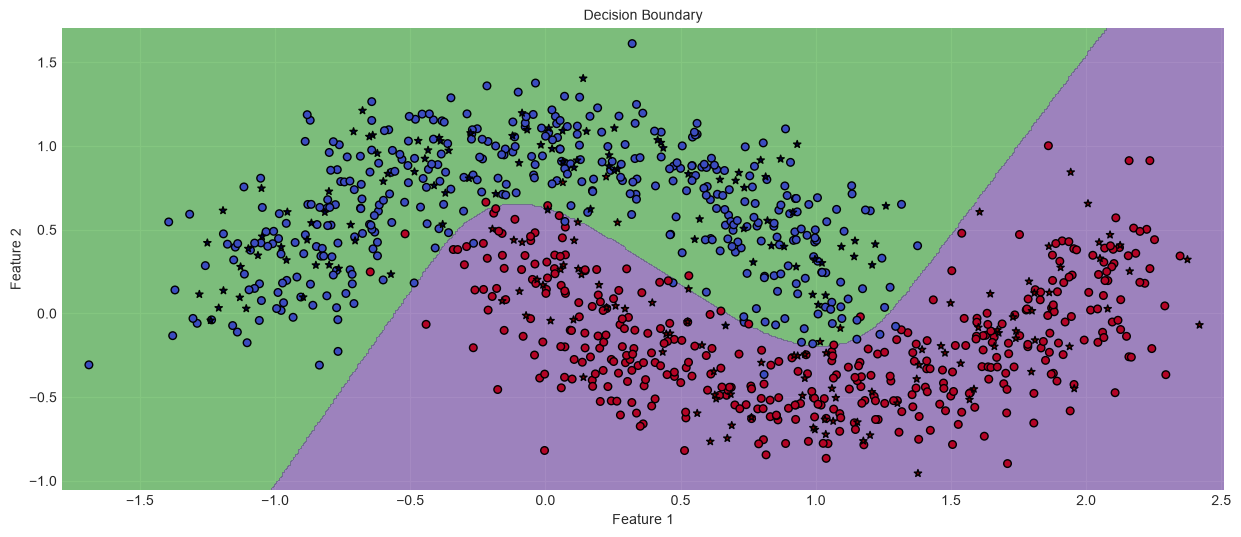

----------------------
# FOR LR = 0.1, NOISE = 0.2, DIM OF HL = 4
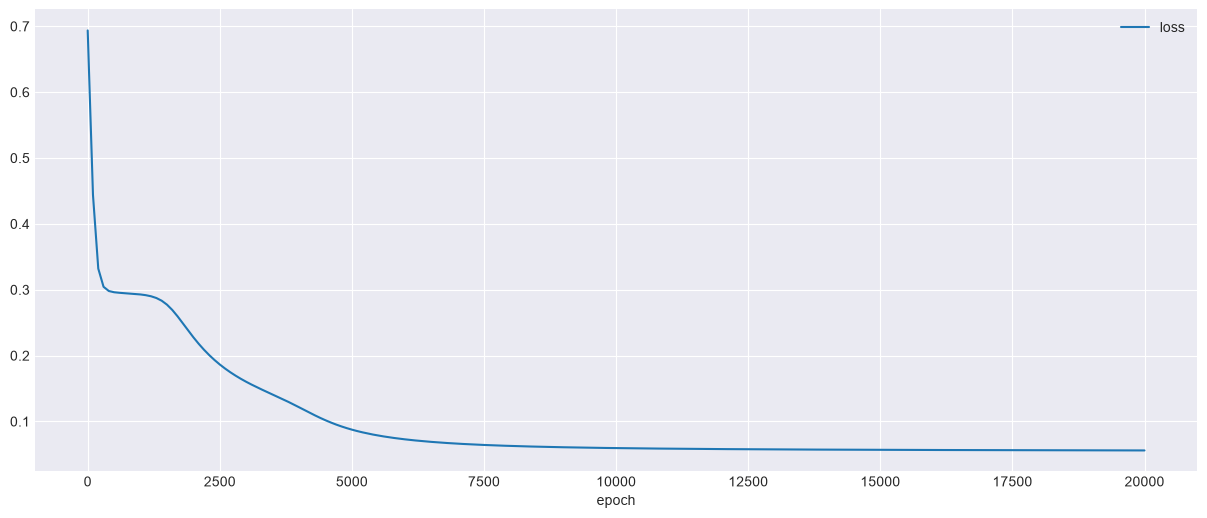

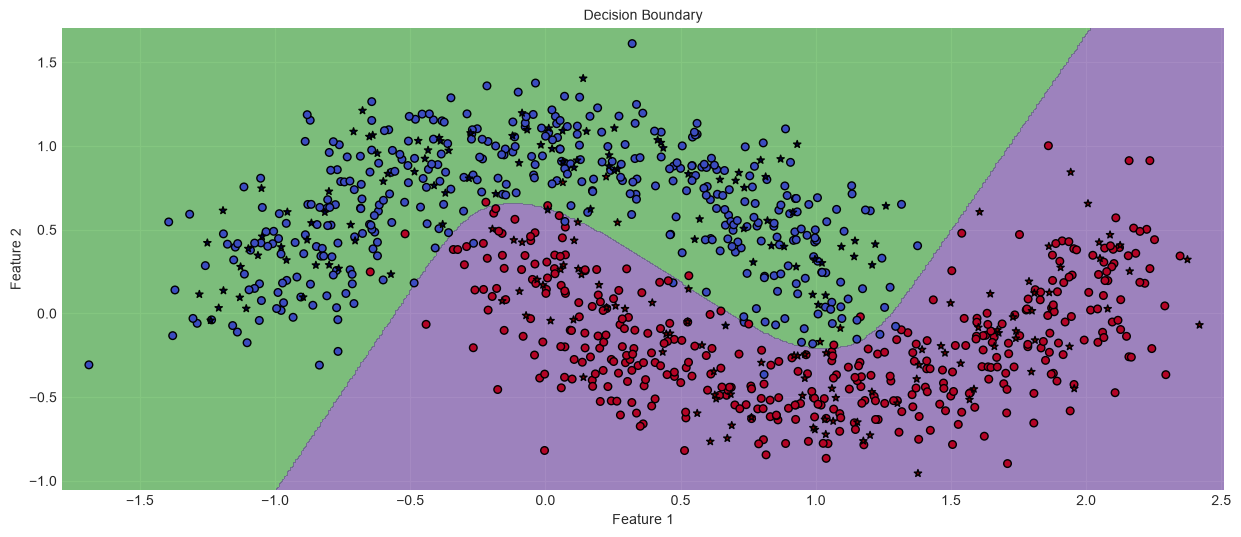